# A17 inputs from BCs

# Imports

In [2]:
import os
import sys

import matplotlib
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib.collections import EllipseCollection, LineCollection
from matplotlib.patches import Rectangle

# import cell_mosaics as cm

In [3]:
sys.path.append("../utils")

import data_io
from colors import colors
from plot import plot_scale_bar
from plot_cells import plot_cell_morphologies
from style import set_rc_params

In [4]:
set_rc_params()

# Data

In [5]:
config = data_io.get_data_config()
version = config.get("version", None)
file_path = data_io.get_file_path(config)

assert os.path.isfile(file_path), file_path

In [14]:
df = pd.read_parquet(file_path, columns=['celltype_final', 'soma_x_um', 'soma_y_um', 'soma_z_um', 'soma_rad_um',
                                       'hull_diameter', 'polar_dens_z', 'cellclass', 'cellclass_final'])
print(df.shape)

(63775, 9)


In [7]:
# read precomputed rbc input data
today ='2026-10-30'
AC_inputs = pd.read_csv(f'/gpfs01/berens/data/data/Eyewire2/ribbons/{today}_AC_ribbon_inputs.csv')

/tmp/ipykernel_2328741/3455333068.py:3: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  AC_inputs = pd.read_csv(f'/gpfs01/berens/data/data/Eyewire2/ribbons/{today}_AC_ribbon_inputs.csv')


In [8]:
fig_dir = f'../figures/AC/v{version}'
os.makedirs(fig_dir, exist_ok=True)

# Parameters

In [9]:
TYPES = ['A17 small', 'A17 large', 'dA17 large']

TYPE_COLORS = {
    'A17 small': "#1613BD",
    'A17 large': "#BB1BC9",
    'dA17 large': "#1A9B9F",
}

# RANDOM_FILL = '#c4c3bf'
# RANDOM_INK = '#5c5b57'

# # Shared field (x_min, x_max, y_min, y_max) in µm: the densest 350 x 350 µm
# # square, i.e. the one maximising the density of the sparser of A17 small and
# # A17 large (25 µm grid search); cells outside it are ignored.
# FIELD = (400, 750, 425, 775)

# # Extent of all somata in the volume (any type), for the overview panels.
# VOLUME = (df.soma_x_um.min(), df.soma_x_um.max(), df.soma_y_um.min(), df.soma_y_um.max())

# N_SIMULATIONS = 99  # Keeley et al. (2020) convention
# SEED = 42

## Check: which A17s are missing from the ribbon input table?

`AC_inputs` was extracted with an older neuron table (`df_all_neurons_2026-08-11-15h`, see
`ac_extraction_20260924_175211.log`). Its `celltype` column is copied from that table's `celltype`,
whereas here A17s are selected by `celltype_final` of `df_all_neurons_2026-09-16-15h`.

In [16]:
df_types = df[df.celltype_final.isin(TYPES)]   # from all neurons df 
len(df_types)

740

In [23]:
A17_inputs = AC_inputs[AC_inputs['celltype'].isin(TYPES)]  # 12 cells are missing
len(A17_inputs['partner_id'].unique())

728

In [18]:
# One type label per partner in the CSV
csv_types = AC_inputs.drop_duplicates('partner_id').set_index('partner_id')['celltype']

df_check = df_types[['celltype_final']].copy()
df_check['in_csv'] = df_check.index.isin(csv_types.index)
df_check['csv_celltype'] = csv_types.reindex(df_check.index).values
df_check['csv_is_A17'] = df_check['csv_celltype'].isin(TYPES)

print(f"A17s in df_all_neurons: {len(df_check)}")
print(f"  in CSV, labelled A17 there:   {(df_check.in_csv & df_check.csv_is_A17).sum()}")
print(f"  in CSV, labelled otherwise:   {(df_check.in_csv & ~df_check.csv_is_A17).sum()}")
print(f"  not in CSV at all:            {(~df_check.in_csv).sum()}")

# Partners labelled A17 in the CSV that are no longer A17 (or no longer exist) in df_all_neurons
csv_A17_ids = csv_types.index[csv_types.isin(TYPES)]
print(f"CSV partners labelled A17 but not A17 in df_all_neurons: {(~csv_A17_ids.isin(df_types.index)).sum()}")

A17s in df_all_neurons: 740
  in CSV, labelled A17 there:   728
  in CSV, labelled otherwise:   0
  not in CSV at all:            12
CSV partners labelled A17 but not A17 in df_all_neurons: 0


# BC type x cell heatmap of ribbon inputs

Same plot as `plot_selected_types_all_cells` in `em_synapses` (`TEMP_plot_selected_types_heatmap.py`),
with the helpers it needs copied here. Cells are grouped into per-type blocks (in `TYPES` order) and
ordered within each block by similarity of their BC-type composition (average-linkage clustering,
correlation distance). Each cell's ribbon counts per BC type are normalized to sum 1.

For now this uses the 690 cells labelled A17 in the ribbon-input CSV (`celltype` column of that CSV).

In [25]:
# Canonical BC type order (as em_synapses.utils.misc.order); matched case-insensitively
# because the export has both 'GluMi' and 'GluMI'.
BC_ORDER = ['t1', 'GluMi', 't2', 't3a', 't3b', 't4', 't5i', 't5o', 't5t', 'XBC',
            't6', 't7', 't8', 't9', 'RBC']

# Ribbon filters (as u24_common.filter_ribbons); 1 / 1 = no filtering.
MIN_RIBBONS_PER_BC = 1  # min ribbons of one BC onto one cell
MIN_BCS_PER_TYPE = 1    # min distinct BCs of one BC type onto one cell

# Filtered heatmap: per cell, BC types providing fewer ribbons than this are set to 0.
MIN_RIBBONS_PER_TYPE = 6

In [26]:
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import pdist


def filter_ribbons(df, min_ribbons_per_bc, min_bcs_per_type):
    """Per cell (partner_id): drop ribbons of BCs with fewer than min_ribbons_per_bc ribbons onto it,
    then ribbons of BC types with fewer than min_bcs_per_type distinct BCs left."""
    n_per_connection = df.groupby(['partner_id', 'cell'])['cell'].transform('size')
    df = df[n_per_connection >= min_ribbons_per_bc]
    n_bcs_per_type = df.groupby(['partner_id', 'cell_type'])['cell'].transform('nunique')
    return df[n_bcs_per_type >= min_bcs_per_type]


def bc_rank(bc_type):
    lower = [t.lower() for t in BC_ORDER]
    return lower.index(str(bc_type).lower()) if str(bc_type).lower() in lower else len(BC_ORDER)


def count_matrix(df):
    """Cell (rows) x BC type (columns) ribbon counts, BC types in canonical order."""
    counts = df.value_counts(['partner_id', 'cell_type']).unstack(fill_value=0)
    return counts[sorted(counts.columns, key=lambda t: (bc_rank(t), t))]


def composition_matrix(counts, min_ribbons_per_type=1):
    """`counts` with entries below min_ribbons_per_type set to 0, each row normalized to sum 1."""
    counts = counts.where(counts >= min_ribbons_per_type, 0)
    totals = counts.sum(axis=1)
    return counts.div(totals.where(totals > 0, 1), axis=0)


def similarity_order(matrix):
    """Row labels of `matrix` in hierarchical-clustering leaf order (correlation distance);
    all-zero rows (no input left after filtering) go last."""
    empty = matrix.sum(axis=1) == 0
    tail = list(matrix.index[empty])
    matrix = matrix[~empty]
    if len(matrix) < 2:
        return list(matrix.index) + tail
    dist = pdist(matrix.to_numpy(), metric='correlation')
    if np.any(np.isnan(dist)):  # constant rows
        return list(matrix.index) + tail
    return list(matrix.index[leaves_list(linkage(np.clip(dist, 0, 2), method='average'))]) + tail

In [27]:
df_heat = filter_ribbons(A17_inputs, MIN_RIBBONS_PER_BC, MIN_BCS_PER_TYPE)
counts = count_matrix(df_heat)
cell_types = df_heat.drop_duplicates('partner_id').set_index('partner_id')['celltype'].reindex(counts.index)
print(cell_types.value_counts()[TYPES])

celltype
A17 small     299
A17 large     385
dA17 large     44
Name: count, dtype: int64


In [30]:
def plot_input_heatmap(composition, cell_types, xlabel='A17 cells'):
    """BC type x cell heatmap of `composition`, cells grouped by type (TYPES order) and ordered
    by similarity within each type, with a type color strip on top."""
    order, blocks = [], []
    for celltype in TYPES:
        cells = composition.index[cell_types == celltype]
        blocks.append((celltype, len(order), len(order) + len(cells)))
        order += similarity_order(composition.loc[cells])
    heat = composition.loc[order].T.to_numpy()  # BC type x cell
    bc_types = list(composition.columns)
    n_cells = len(order)

    fig = plt.figure(figsize=(7.4, 2.2))
    gs = fig.add_gridspec(2, 2, height_ratios=(1, 14), width_ratios=(60, 1), hspace=0.04, wspace=0.015)
    ax_strip = fig.add_subplot(gs[0, 0])
    ax_heat = fig.add_subplot(gs[1, 0], sharex=ax_strip)
    ax_cbar = fig.add_subplot(gs[1, 1])

    strip = np.array([matplotlib.colors.to_rgba(TYPE_COLORS[cell_types[c]]) for c in order])[None]
    ax_strip.imshow(strip, aspect='auto', extent=(0, n_cells, 0, 1), interpolation='none')
    ax_strip.axis('off')
    for celltype, start, end in blocks:
        ax_strip.text((start + end) / 2, 1.4, f"{celltype}", ha='center', va='bottom',
                      fontsize=7)

    im = ax_heat.imshow(heat, aspect='auto', cmap='Greys', interpolation='none', rasterized=True,
                        extent=(0, n_cells, len(bc_types), 0), vmin=0)
    for _, start, _ in blocks[1:]:
        ax_heat.axvline(start, color='k', lw=0.7)
        ax_strip.axvline(start, color='k', lw=0.7)
    ax_heat.set_yticks(np.arange(len(bc_types)) + 0.5, bc_types, fontsize=6)
    ax_heat.tick_params(axis='y', length=0, pad=2)
    ax_heat.set_xticks([])
    ax_heat.set_xlabel(xlabel, fontsize=7, labelpad=2)
    ax_heat.set_ylabel('BC type', fontsize=7, labelpad=2)
    ax_heat.spines[['left', 'bottom']].set_visible(False)

    cbar = fig.colorbar(im, cax=ax_cbar)
    cbar.set_label('Fraction of\nribbon inputs', fontsize=6)
    cbar.ax.tick_params(labelsize=6)
    cbar.outline.set_linewidth(0.5)
    return fig

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

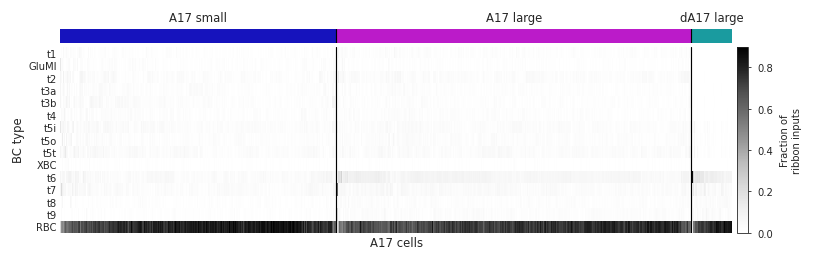

In [31]:
fig = plot_input_heatmap(composition_matrix(counts), cell_types)
fig.savefig(f'{fig_dir}/A17_bc_inputs_heatmap.svg', dpi=600, bbox_inches='tight')
fig.savefig(f'{fig_dir}/A17_bc_inputs_heatmap.png', dpi=600, bbox_inches='tight')
plt.show()

## Filtered: BC types with < `MIN_RIBBONS_PER_TYPE` ribbons onto a cell removed

Per cell, BC types providing fewer than `MIN_RIBBONS_PER_TYPE` ribbons are set to 0 before
normalizing, so fractions are of the remaining ribbons.

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

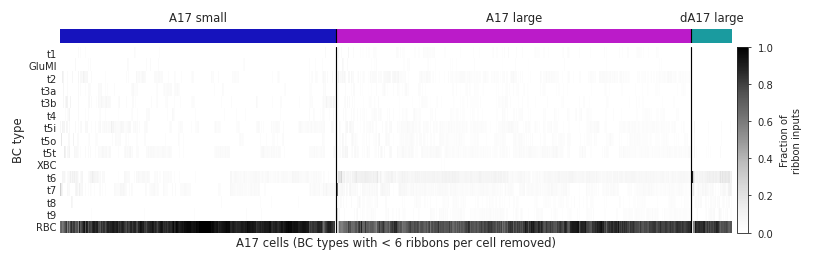

In [32]:
fig = plot_input_heatmap(composition_matrix(counts, MIN_RIBBONS_PER_TYPE), cell_types,
                         xlabel=f'A17 cells (BC types with < {MIN_RIBBONS_PER_TYPE} ribbons per cell removed)')
fig.savefig(f'{fig_dir}/A17_bc_inputs_heatmap_min{MIN_RIBBONS_PER_TYPE}.svg', dpi=600, bbox_inches='tight')
fig.savefig(f'{fig_dir}/A17_bc_inputs_heatmap_min{MIN_RIBBONS_PER_TYPE}.png', dpi=600, bbox_inches='tight')
plt.show()

# Ribbon inputs per BC type, by A17 type

Unfiltered counts. Means include cells receiving no ribbons from a BC type (as 0).

In [ ]:
by_type = counts.groupby(cell_types)
frac_cells = (by_type.agg(lambda x: (x > 0).mean()) * 100).T[TYPES]  # % of A17 cells with >= 1 ribbon
mean_ribbons = by_type.mean().T[TYPES]
sd_ribbons = by_type.std().T[TYPES]

pd.concat({'% cells with input': frac_cells, 'mean ribbons per BC': mean_ribbons,
           'SD': sd_ribbons}, axis=1).round(1)

% cells with input                      mean ribbons per cell  \
celltype           A17 small A17 large dA17 large             A17 small   
cell_type                                                                 
t1                      78.6      96.6        0.0                   1.7   
GluMI                   78.9      87.3        0.0                   2.1   
t2                      92.0      99.2        4.5                   4.0   
t3a                     91.6      96.6        9.1                   3.4   
t3b                     94.0      95.3       11.4                   4.1   
t4                      89.0      95.6       13.6                   3.0   
t5i                    100.0      99.2       72.7                   5.4   
t5o                     93.6      98.2       63.6                   3.3   
t5t                     98.0      99.0       68.2                   5.6   
XBC                     46.8      55.3        9.1                   0.7   
t6                     100.0     100.0      100.0                   7.0   
t7                      98.7     100.0      100.0                   5.6   
t8                      73.6      96.9       95.5                   1.7   
t9                      78.3      97.7       97.7                   1.6   
RBC                    100.0     100.0      100.0                 180.2   

                                      SD                       
celltype  A17 large dA17 large A17 small A17 large dA17 large  
cell_type                                                      
t1              4.2        0.0       1.5       2.8        0.0  
GluMI           2.4        0.0       1.8       1.9        0.0  
t2              8.2        0.1       3.2       4.8        0.8  
t3a             4.3        0.2       2.5       2.5        1.1  
t3b             3.9        0.3       3.1       2.6        1.1  
t4              4.8        0.2       2.2       3.1        0.4  
t5i             8.0        2.5       2.6       4.2        5.5  
t5o             6.6        2.0       2.2       3.6        3.4  
t5t             9.3        2.6       3.2       4.8        5.0  
XBC             1.0        0.2       0.8       1.2        0.8  
t6             26.6       43.7       3.6      21.8       52.7  
t7             11.4       12.8       3.1       6.0        7.0  
t8              5.3        7.2       1.6       3.3        3.1  
t9              6.9        7.1       1.5       4.3        5.3  
RBC           272.6      214.4      54.5      80.3       84.5

In [35]:
def grouped_bars(ax, values, errors=None):
    """One group of bars per row of `values` (BC types), one bar per column (A17 types)."""
    width = 0.8 / len(TYPES)
    x = np.arange(len(values))
    for k, celltype in enumerate(TYPES):
        ax.bar(x + (k - (len(TYPES) - 1) / 2) * width, values[celltype], width=width,
               color=TYPE_COLORS[celltype], linewidth=0, label=celltype,
               yerr=None if errors is None else errors[celltype], capsize=0,
               error_kw={'elinewidth': 0.5, 'ecolor': 'k'})
    ax.set_xticks(x, values.index, fontsize=6)
    ax.tick_params(axis='y', labelsize=6)
    ax.set_xlim(-0.5, len(values) - 0.5)

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

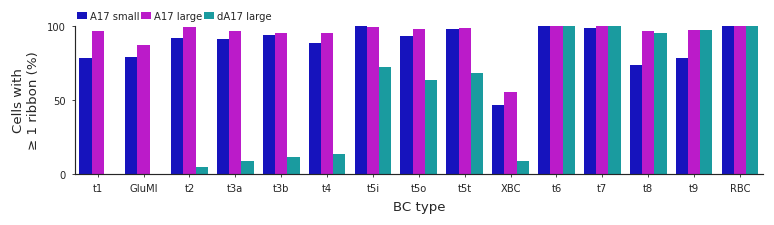

In [36]:
fig, ax = plt.subplots(figsize=(7.4, 1.6))
grouped_bars(ax, frac_cells)
ax.set(ylim=(0, 100), yticks=[0, 50, 100], xlabel='BC type', ylabel='Cells with\n≥ 1 ribbon (%)')
ax.legend(fontsize=6, ncols=3, loc='lower left', bbox_to_anchor=(0, 1.02), handlelength=1)

fig.savefig(f'{fig_dir}/A17_bc_inputs_fraction_cells.svg', dpi=600, bbox_inches='tight')
fig.savefig(f'{fig_dir}/A17_bc_inputs_fraction_cells.png', dpi=600, bbox_inches='tight')
plt.show()

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

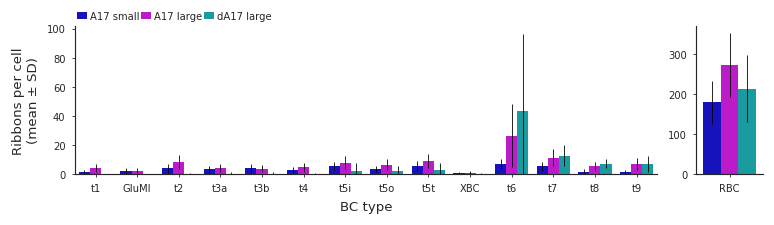

In [37]:
# RBC input is ~10x larger than any other BC type, so it gets its own axis.
fig, (ax, ax_rbc) = plt.subplots(1, 2, figsize=(7.4, 1.6), width_ratios=(14, 1.6), gridspec_kw={'wspace': 0.12})
cone_bcs = [t for t in mean_ribbons.index if t != 'RBC']
grouped_bars(ax, mean_ribbons.loc[cone_bcs], sd_ribbons.loc[cone_bcs])
grouped_bars(ax_rbc, mean_ribbons.loc[['RBC']], sd_ribbons.loc[['RBC']])
ax.set(ylim=(0, None), xlabel='BC type', ylabel='Ribbons per cell\n(mean ± SD)')
ax_rbc.set(ylim=(0, None))
ax.legend(fontsize=6, ncols=3, loc='lower left', bbox_to_anchor=(0, 1.02), handlelength=1)

fig.savefig(f'{fig_dir}/A17_bc_inputs_mean_per_cell.svg', dpi=600, bbox_inches='tight')
fig.savefig(f'{fig_dir}/A17_bc_inputs_mean_per_cell.png', dpi=600, bbox_inches='tight')
plt.show()